# When students are stressed, do they seek AI over their professor/TA?

## Idea

Students were asked how often, in the past week, they went to AI for help **without** going to their professor or TA. They answered this for three things: understanding a course concept, understanding what an assignment is asking, and figuring out how to solve a problem.

We compared students who felt very stressed about their coursework with students who felt less stressed.

## Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

df = pd.read_csv("../../data/uncleaned_data.csv")

## Data Cleaning

We created groups for stressed/less-stressed students and groups (based on score) for how often students consulted AI before professor/TA.

- [FI]–[FK]: For the question about consulting AI, there were 3 tasks that had choices (Never | Rarely | Sometimes | Often | All the time). Those choices were then converted into values 0-4 and averaged per student. Again we grouped students into buckets based on that averaged score.
    - Rarely: ($0 \le$ score $\le 1$) (mostly Never / Rarely)
    - Sometimes: ($1 \lt$ score $\le 2$)
    - Often: ($2 \lt$ score) (mostly Often / All the time)

- [FG]: The single question that we used to determine stress [FG] had values 1-5. Since the upper and lower ends had few students we grouped them into less stress (1-3) and very stress (4-5).

In [2]:
# look through the df to find the 3 "AI without your professor or TA" columns and the stress column
skip_cols = [c for c in df.columns if "without consulting your professor or TA" in c]
stress_col = [c for c in df.columns if "[Stress about coursework]" in c][0]

# turn each answer into a number, anything else (blank, prefer not to answer) becomes NaN
to_number = {"Never": 0, "Rarely": 1, "Sometimes": 2, "Often": 3, "All the time": 4}
numbers = pd.DataFrame()
for col in skip_cols:
    numbers[col] = df[col].map(to_number)

# break down the groups like stated in the above markdown cell
ai_instead = pd.cut(numbers.mean(axis=1), bins=[-1, 1, 2, 4], labels=["Rarely", "Sometimes", "Often"])
stress = pd.cut(pd.to_numeric(df[stress_col], errors="coerce"), bins=[0, 3, 5],
                labels=["Less stressed (1-3)", "Very stressed (4-5)"])

# One row per student. Drop students who skipped either question.
data = pd.DataFrame({
    "ai_instead": ai_instead,
    "stress": stress,
}).dropna()

## Build and Plot

ai_instead           Rarely  Sometimes  Often
stress                                       
Less stressed (1-3)      13         17      4
Very stressed (4-5)       7         17     25

ai_instead           Rarely  Sometimes  Often
stress                                       
Less stressed (1-3)    38.0       50.0   12.0
Very stressed (4-5)    14.0       35.0   51.0

Squares out of 100:
ai_instead           Rarely  Sometimes  Often
stress                                       
Less stressed (1-3)      38         50     12
Very stressed (4-5)      14         35     51


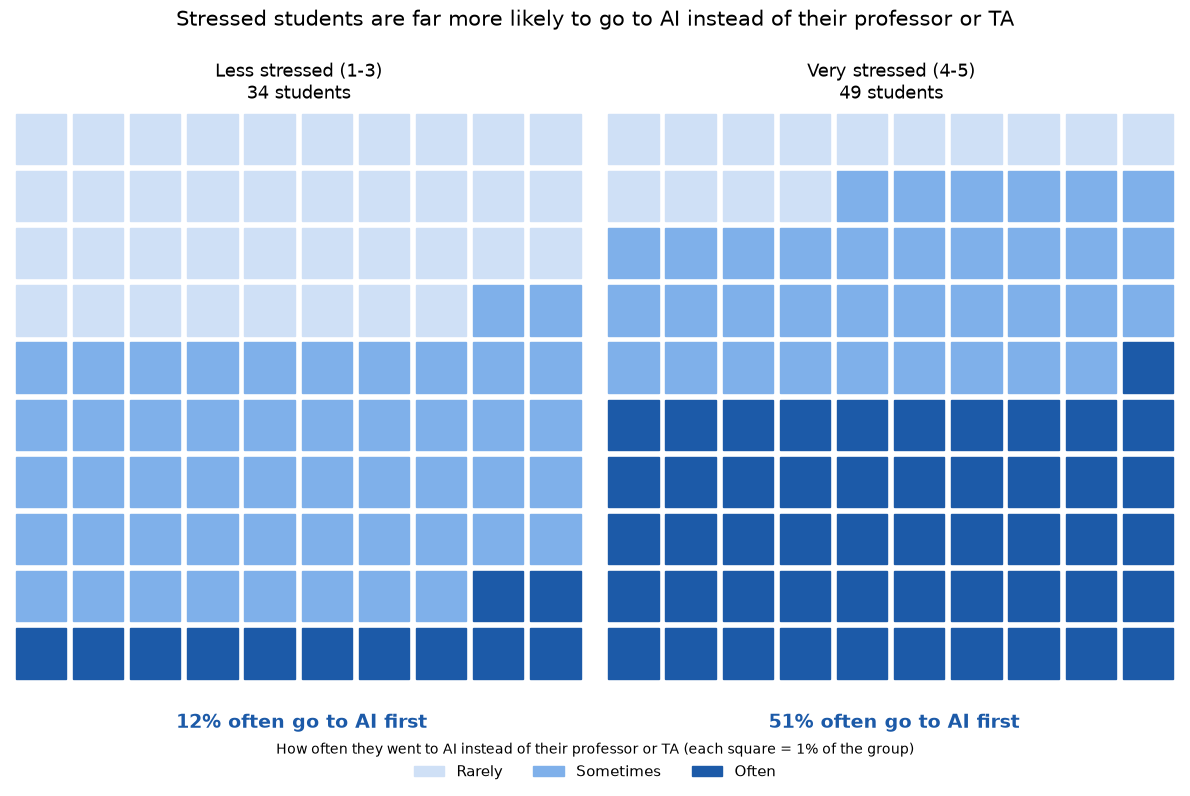


Understanding a course concept: Less stressed (1-3) 26%, Very stressed (4-5) 65%
Understanding what an assignment is asking: Less stressed (1-3) 12%, Very stressed (4-5) 31%
Figuring out how to solve a problem: Less stressed (1-3) 9%, Very stressed (4-5) 41%


In [3]:
# order
stress_order = ["Less stressed (1-3)", "Very stressed (4-5)"]
ai_order = ["Rarely", "Sometimes", "Often"]

# lighter = less AI, darker = more AI
colors = {"Rarely": "#cfe0f6", "Sometimes": "#7fb0ea", "Often": "#1c5aa8"}

# number and percent of students in each group
table = pd.crosstab(data["stress"], data["ai_instead"]).loc[stress_order, ai_order]
percent = (table.div(table.sum(axis=1), axis=0) * 100).round(0)
print(table)
print()
print(percent)

# both groups get a 10 x 10 grid, so each square is 1% of that group
columns = 10
rows = 10

# turn each group's percents into 100 whole squares
# round down first, then give any leftover squares to the answers that lost the most from rounding
square_counts = percent.copy()
for group in stress_order:
    exact = table.loc[group] / table.loc[group].sum() * 100
    whole = exact.astype(int)
    leftover = 100 - whole.sum()
    biggest_remainders = (exact - whole).sort_values(ascending=False).index[:leftover]
    whole[biggest_remainders] += 1
    square_counts.loc[group] = whole
square_counts = square_counts.astype(int)
print()
print("Squares out of 100:")
print(square_counts)

fig, axes = plt.subplots(1, 2, figsize=(12, 8))

i = 0
for group in stress_order:
    ax = axes[i]

    # 100 squares, Rarely first and Often last so each color is one block
    squares = []
    for answer in ai_order:
        squares += [answer] * square_counts.loc[group, answer]

    # fill left to right, top to bottom
    for n, answer in enumerate(squares):
        x = n % columns
        y = rows - 1 - n // columns
        ax.add_patch(Rectangle((x, y), 0.88, 0.88, color=colors[answer]))

    ax.set_xlim(-0.1, columns)
    ax.set_ylim(-0.1, rows)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(f"{group}\n{table.loc[group].sum()} students", fontsize=13)

    # the one number to remember, under each grid
    often = percent.loc[group, "Often"]
    ax.text(columns / 2, -0.6, f"{often:.0f}% often go to AI first", ha="center", va="top",
            fontsize=14, fontweight="bold", color=colors["Often"])

    i += 1

legend = [Patch(color=colors[a], label=a) for a in ai_order]
fig.legend(handles=legend, loc="lower center", ncol=3, frameon=False, fontsize=11,
           title="How often they went to AI instead of their professor or TA (each square = 1% of the group)",
           bbox_to_anchor=(0.5, 0))
fig.suptitle("Stressed students are far more likely to go to AI instead of their professor or TA", fontsize=15)
# leave room at the top for the title and at the bottom for the legend
plt.tight_layout(rect=[0, 0.1, 1, 0.94])
plt.show()

# same thing for each task on its own: percent who said Often or All the time
print()
for col in skip_cols:
    task = col.split("[")[-1].strip("]")
    answered = pd.DataFrame({"stress": stress, "answer": numbers[col]}).dropna()
    often_pct = (answered["answer"] >= 3).groupby(answered["stress"], observed=True).mean() * 100
    print(f"{task}: " + ", ".join(f"{g} {p:.0f}%" for g, p in often_pct.loc[stress_order].items()))

## Conclusion

Each grid is one group of students (less stressed / stressed) scaled to 100 squared so they can be compared directly. The darker the square the more often students went to AI instead of their professor/TA. The less stressed group had 34 students and only about 12 out of every 100 often went to AI first. In the stressed group there are 49 students, the dark block takes up half the grid telling us that 51 out of every 100 students often go to AI first. What this can tell use is that when students are stressed, AI replaces their professor or TA. This suggests that pressure, and not just convenience, is one reason some students use AI more than others.